In [35]:
%pip install openpyxl


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [36]:
import pandas as pd

df = pd.read_excel("Professional_Associations.xlsx")

df.head()


,Association Name,Association URL,Certification (Y/N),Career Center URL,NAICS Code,O*Net Code
0,Accounting & Financial Women's Alliance (AFWA),https://www.afwa.org/,n,https://www.afwa.org/career/,541000,13-2011.00
1,American Council on Renewable Energy (ACORE),https://acore.org,NaN,NaN,324000,11-9041.01
2,CMT Association (CMTA),https://cmtassociation.org/,y,NaN,541000,13-2051.00
3,IPC - Association Connecting Electronics Indu...,https://www.ipc.org/,y,NaN,449000,15-1299.09
4,National Association of Special Education Tea...,https://www.naset.com/,NaN,https://www.naset.com/partners/job-postings/,611000,25-2058.00


In [37]:
df.shape

(2463, 6)

In [38]:
df.columns

Index(['Association Name', 'Association URL', 'Certification (Y/N)',
       'Career Center URL', 'NAICS Code', 'O*Net Code'],
      dtype='str')

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2463 entries, 0 to 2462
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Association Name     2463 non-null   str  
 1   Association URL      2460 non-null   str  
 2   Certification (Y/N)  1138 non-null   str  
 3   Career Center URL    794 non-null    str  
 4   NAICS Code           2463 non-null   int64
 5   O*Net Code           2463 non-null   str  
dtypes: int64(1), str(5)
memory usage: 115.6 KB


In [40]:
df.isnull().sum()

Association Name          0
Association URL           3
Certification (Y/N)    1325
Career Center URL      1669
NAICS Code                0
O*Net Code                0
dtype: int64

In [41]:
df.head()

,Association Name,Association URL,Certification (Y/N),Career Center URL,NAICS Code,O*Net Code
0,Accounting & Financial Women's Alliance (AFWA),https://www.afwa.org/,n,https://www.afwa.org/career/,541000,13-2011.00
1,American Council on Renewable Energy (ACORE),https://acore.org,NaN,NaN,324000,11-9041.01
2,CMT Association (CMTA),https://cmtassociation.org/,y,NaN,541000,13-2051.00
3,IPC - Association Connecting Electronics Indu...,https://www.ipc.org/,y,NaN,449000,15-1299.09
4,National Association of Special Education Tea...,https://www.naset.com/,NaN,https://www.naset.com/partners/job-postings/,611000,25-2058.00


In [42]:
df = df.rename(columns={
    "Association Name": "association",
    "Association URL": "association_url",
    "Certification (Y/N)": "certification",
    "Career Center URL": "career_center_url",
    "NAICS Code": "naics",
    "O*Net Code": "onet"
})

df.head()

,association,association_url,certification,career_center_url,naics,onet
0,Accounting & Financial Women's Alliance (AFWA),https://www.afwa.org/,n,https://www.afwa.org/career/,541000,13-2011.00
1,American Council on Renewable Energy (ACORE),https://acore.org,NaN,NaN,324000,11-9041.01
2,CMT Association (CMTA),https://cmtassociation.org/,y,NaN,541000,13-2051.00
3,IPC - Association Connecting Electronics Indu...,https://www.ipc.org/,y,NaN,449000,15-1299.09
4,National Association of Special Education Tea...,https://www.naset.com/,NaN,https://www.naset.com/partners/job-postings/,611000,25-2058.00


In [43]:
print("Total rows:", len(df))
print("Unique associations:", df["association"].nunique())
print("Unique O*NET codes:", df["onet"].nunique())

Total rows: 2463
Unique associations: 2461
Unique O*NET codes: 613


In [44]:
df["onet"].value_counts().head(10)

onet
29-1141.00    59
29-1229.00    37
23-1011.00    35
11-9111.00    33
13-1199.00    27
11-2021.00    27
11-9033.00    26
13-2011.00    25
19-3011.00    25
29-1249.00    23
Name: count, dtype: int64

In [45]:
duplicates = df.duplicated(subset=["association", "onet"]).sum()

print("Duplicate association-occupation relationships:", duplicates)

Duplicate association-occupation relationships: 1


In [46]:
df = df.drop_duplicates(subset=["association", "onet"])

print("Rows after removing duplicate:", len(df))

Rows after removing duplicate: 2462


In [47]:
network_df = df[["association", "onet"]].copy()

network_df.head()

,association,onet
0,Accounting & Financial Women's Alliance (AFWA),13-2011.00
1,American Council on Renewable Energy (ACORE),11-9041.01
2,CMT Association (CMTA),13-2051.00
3,IPC - Association Connecting Electronics Indu...,15-1299.09
4,National Association of Special Education Tea...,25-2058.00


In [48]:
print("Rows:", len(network_df))
print("Unique associations:", network_df["association"].nunique())
print("Unique occupations:", network_df["onet"].nunique())

Rows: 2462
Unique associations: 2461
Unique occupations: 613


In [49]:
import networkx as nx

In [50]:
G = nx.Graph()

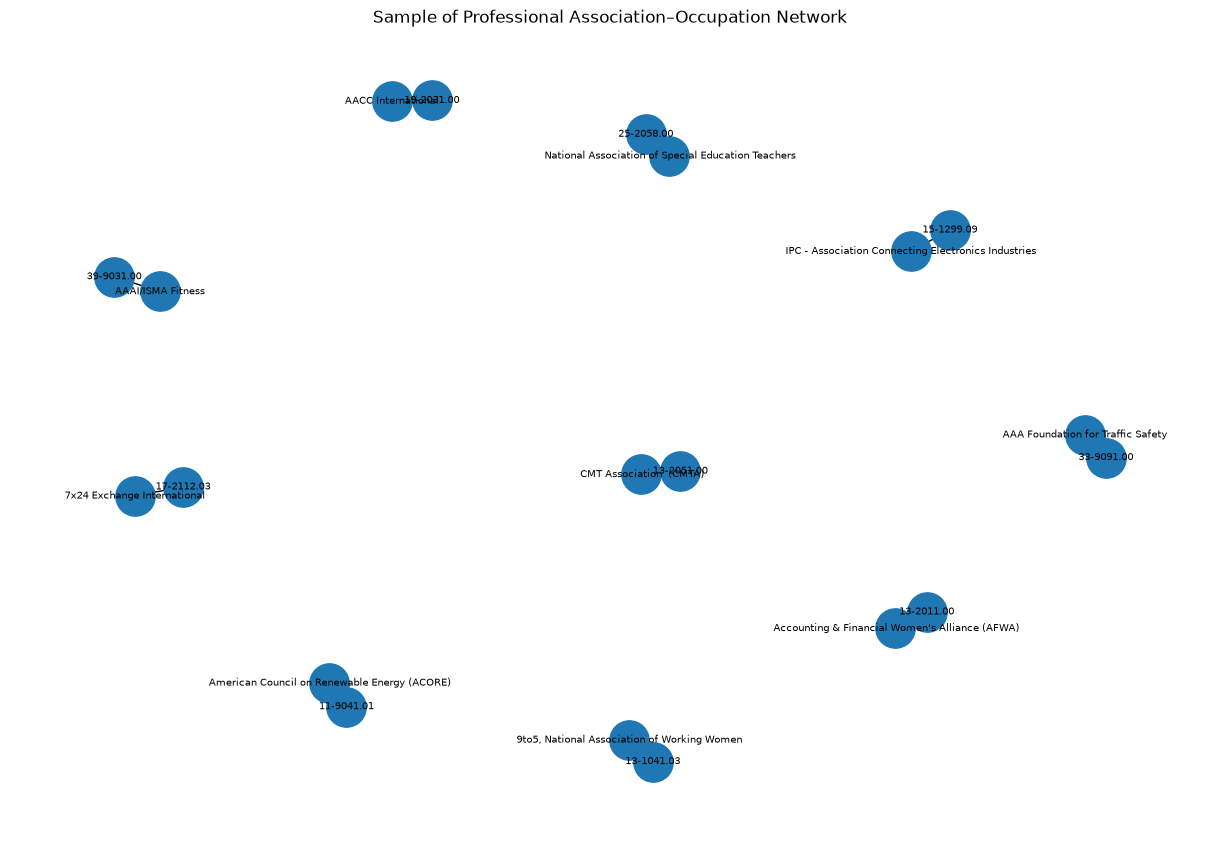

In [73]:
import matplotlib.pyplot as plt

# Take a small sample of 10 associations
sample_associations = list(network_df["association"].unique())[:10]

# Get the occupations connected to those associations
sample_nodes = set(sample_associations)

for association in sample_associations:
    sample_nodes.update(G.neighbors(association))

# Create a smaller graph
sample_G = G.subgraph(sample_nodes)

# Draw the graph
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(sample_G, seed=42)

nx.draw(
    sample_G,
    pos,
    with_labels=True,
    node_size=800,
    font_size=7
)

plt.title("Sample of Professional Association–Occupation Network")
plt.show()

In [74]:
for association in network_df["association"].unique():
    G.add_node(association, node_type="association")

In [75]:
for occupation in network_df["onet"].unique():
    G.add_node(occupation, node_type="occupation")

In [76]:
for _, row in network_df.iterrows():
    G.add_edge(row["association"], row["onet"])

In [77]:
print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())
print("Association nodes:", len(network_df["association"].unique()))
print("Occupation nodes:", len(network_df["onet"].unique()))

Total nodes: 3074
Total edges: 2462
Association nodes: 2461
Occupation nodes: 613


In [78]:
print("Is bipartite:", nx.is_bipartite(G))

Is bipartite: True


In [79]:
degree = dict(G.degree())

# Separate associations and occupations
association_degree = {
    node: degree[node]
    for node in G.nodes
    if G.nodes[node]["node_type"] == "association"
}

occupation_degree = {
    node: degree[node]
    for node in G.nodes
    if G.nodes[node]["node_type"] == "occupation"
}

In [80]:
top_occupations = sorted(
    occupation_degree.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for occupation, connections in top_occupations:
    print(occupation, "→", connections, "associations")

29-1141.00 → 59 associations
29-1229.00 → 37 associations
23-1011.00 → 35 associations
11-9111.00 → 33 associations
13-1199.00 → 27 associations
11-2021.00 → 27 associations
11-9033.00 → 26 associations
13-2011.00 → 25 associations
19-3011.00 → 25 associations
29-1249.00 → 23 associations


In [81]:
top_associations = sorted(
    association_degree.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for association, connections in top_associations:
    print(association, "→", connections, "occupations")

American Clean Power (ACP) → 2 occupations
 Accounting & Financial Women's Alliance (AFWA) → 1 occupations
 American Council on Renewable Energy (ACORE) → 1 occupations
 CMT Association  (CMTA) → 1 occupations
 IPC - Association Connecting Electronics Industries  → 1 occupations
 National Association of Special Education Teachers → 1 occupations
7x24 Exchange International → 1 occupations
9to5, National Association of Working Women → 1 occupations
AAA Foundation for Traffic Safety → 1 occupations
AAAI/ISMA Fitness → 1 occupations


In [82]:
top_occupation_codes = [occupation for occupation, connections in top_occupations]

print(top_occupation_codes)

['29-1141.00', '29-1229.00', '23-1011.00', '11-9111.00', '13-1199.00', '11-2021.00', '11-9033.00', '13-2011.00', '19-3011.00', '29-1249.00']


In [83]:
df[df["onet"].isin(top_occupation_codes)][["onet"]].drop_duplicates().sort_values("onet")

,onet
390,11-2021.00
75,11-9033.00
15,11-9111.00
344,13-1199.00
0,13-2011.00
92,19-3011.00
57,23-1011.00
24,29-1141.00
65,29-1229.00
150,29-1249.00


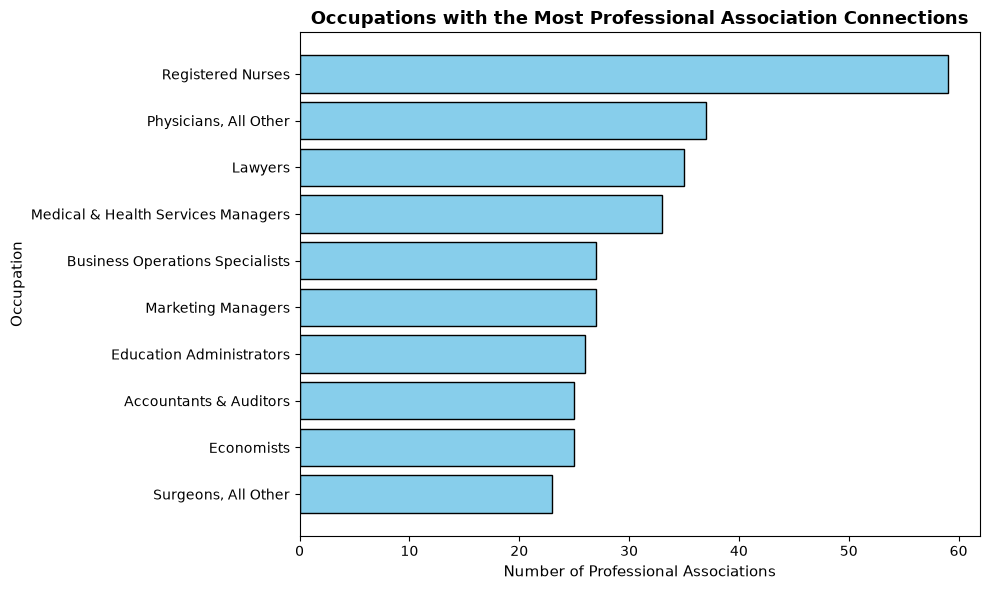

In [95]:

occupation_names = {
    '29-1141.00': 'Registered Nurses',
    '29-1229.00': 'Physicians, All Other',
    '23-1011.00': 'Lawyers',
    '11-9111.00': 'Medical & Health Services Managers',
    '13-1199.00': 'Business Operations Specialists',
    '11-2021.00': 'Marketing Managers',
    '11-9033.00': 'Education Administrators',
    '13-2011.00': 'Accountants & Auditors',
    '19-3011.00': 'Economists',
    '29-1249.00': 'Surgeons, All Other'
}

top = top_occupations

# Extract readable titles using the dictionary (falls back to code if missing)
labels = [occupation_names.get(x[0], x[0]) for x in top]
values = [x[1] for x in top]

plt.figure(figsize=(10, 6))

# Plot horizontal bars with readable labels
plt.barh(labels[::-1], values[::-1], color='skyblue', edgecolor='black')

plt.xlabel("Number of Professional Associations", fontsize=11)
plt.ylabel("Occupation", fontsize=11)
plt.title("Occupations with the Most Professional Association Connections", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

In [96]:
degree_centrality = nx.degree_centrality(G)

In [97]:
top_occupation_centrality = sorted(
    [
        (node, degree_centrality[node])
        for node in occupation_degree
    ],
    key=lambda x: x[1],
    reverse=True
)[:10]

for occupation, score in top_occupation_centrality:
    print(occupation, "→", round(score, 4))

29-1141.00 → 0.0192
29-1229.00 → 0.012
23-1011.00 → 0.0114
11-9111.00 → 0.0107
13-1199.00 → 0.0088
11-2021.00 → 0.0088
11-9033.00 → 0.0085
13-2011.00 → 0.0081
19-3011.00 → 0.0081
29-1249.00 → 0.0075


In [98]:
top_association_centrality = sorted(
    [
        (node, degree_centrality[node])
        for node in association_degree
    ],
    key=lambda x: x[1],
    reverse=True
)[:10]

for association, score in top_association_centrality:
    print(association, "→", round(score, 4))

American Clean Power (ACP) → 0.0007
 Accounting & Financial Women's Alliance (AFWA) → 0.0003
 American Council on Renewable Energy (ACORE) → 0.0003
 CMT Association  (CMTA) → 0.0003
 IPC - Association Connecting Electronics Industries  → 0.0003
 National Association of Special Education Teachers → 0.0003
7x24 Exchange International → 0.0003
9to5, National Association of Working Women → 0.0003
AAA Foundation for Traffic Safety → 0.0003
AAAI/ISMA Fitness → 0.0003


In [99]:
betweenness = nx.betweenness_centrality(G)

In [100]:
top_association_betweenness = sorted(
    [
        (node, betweenness[node])
        for node in association_degree
    ],
    key=lambda x: x[1],
    reverse=True
)[:10]

for association, score in top_association_betweenness:
    print(association, "→", round(score, 6))

American Clean Power (ACP) → 1e-06
 Accounting & Financial Women's Alliance (AFWA) → 0.0
 American Council on Renewable Energy (ACORE) → 0.0
 CMT Association  (CMTA) → 0.0
 IPC - Association Connecting Electronics Industries  → 0.0
 National Association of Special Education Teachers → 0.0
7x24 Exchange International → 0.0
9to5, National Association of Working Women → 0.0
AAA Foundation for Traffic Safety → 0.0
AAAI/ISMA Fitness → 0.0


In [101]:
top_occupation_betweenness = sorted(
    [
        (node, betweenness[node])
        for node in occupation_degree
    ],
    key=lambda x: x[1],
    reverse=True
)[:10]

for occupation, score in top_occupation_betweenness:
    print(occupation, "→", round(score, 6))

29-1141.00 → 0.000362
29-1229.00 → 0.000141
23-1011.00 → 0.000126
11-9111.00 → 0.000112
13-1199.00 → 7.4e-05
11-2021.00 → 7.4e-05
11-9033.00 → 6.9e-05
13-2011.00 → 6.4e-05
19-3011.00 → 6.4e-05
29-1249.00 → 5.4e-05


In [102]:
results = []

for occupation, connections in top_occupations:
    results.append({
        "O*NET Code": occupation,
        "Connections": connections,
        "Degree Centrality": round(degree_centrality[occupation], 4),
        "Betweenness Centrality": round(betweenness[occupation], 6)
    })

results_df = pd.DataFrame(results)

results_df

,O*NET Code,Connections,Degree Centrality,Betweenness Centrality
0,29-1141.00,59,0.0192,0.000362
1,29-1229.00,37,0.0120,0.000141
2,23-1011.00,35,0.0114,0.000126
3,11-9111.00,33,0.0107,0.000112
4,13-1199.00,27,0.0088,0.000074
5,11-2021.00,27,0.0088,0.000074
6,11-9033.00,26,0.0085,0.000069
7,13-2011.00,25,0.0081,0.000064
8,19-3011.00,25,0.0081,0.000064
9,29-1249.00,23,0.0075,0.000054


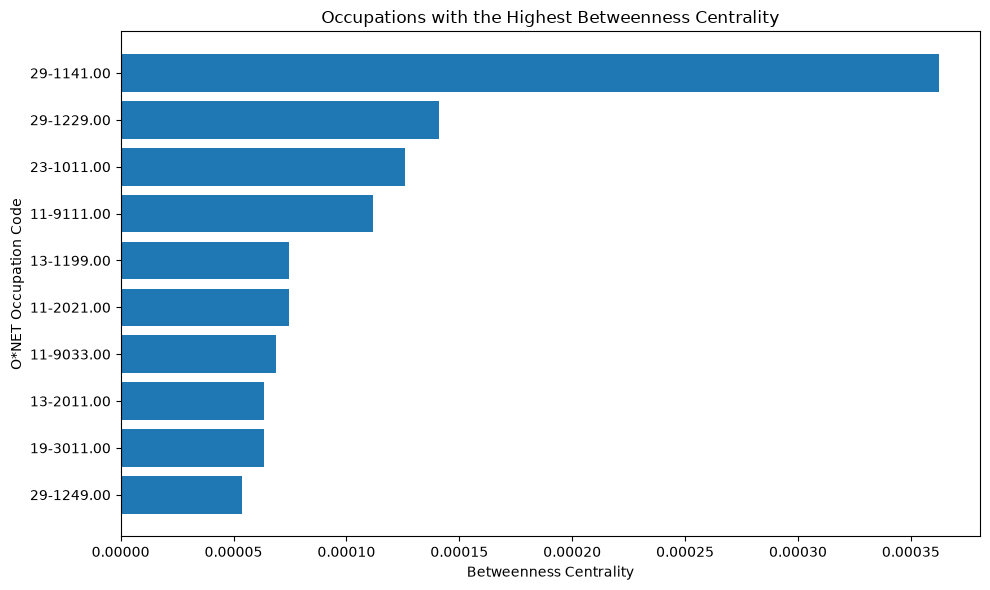

In [103]:
top = top_occupation_betweenness[:10]

codes = [x[0] for x in top]
values = [x[1] for x in top]

plt.figure(figsize=(10, 6))
plt.barh(codes[::-1], values[::-1])

plt.xlabel("Betweenness Centrality")
plt.ylabel("O*NET Occupation Code")
plt.title("Occupations with the Highest Betweenness Centrality")

plt.tight_layout()
plt.show()

In [104]:
for occupation in top_occupations[:3]:
    print("\n", occupation[0], "—", occupation[1], "associations")
    
    connected = list(G.neighbors(occupation[0]))
    
    for association in connected:
        print("  -", association)


 29-1141.00 — 59 associations
  - AMDA - Dedicated to Long Term Care Medicine
  - ANA Enterprise (ANA)
  - Academy of Lactation Policy and Practice
  - American Academy of Ambulatory Care Nursing (AAACN)
  - American Assisted Living Nurses Association (AALNA)
  - American Association of Legal Nurse Consultants (AALNC)
  - American Association of Managed Care Nurses, Inc.
  - American Association of Nurse Life Care Planners
  - American Board of Certification for Gastroenterology Nurses (ABCGN)
  - American Board of Managed Care Nursing (ABMCN)
  - American Holistic Nurses' Association (AHNA)
  - American Nephrology Nurses Association (ANNA)
  - American Organization of Nurse Executives
  - American Psychiatric Nurses Association (APNA)
  - American Society for Ophthalmic Registered Nurses (ASORN)
  - American Society of PeriAnesthesia Nurses (ASPN)
  - American Society of Plastic Surgical Nurses (ASPSN)
  - Association for the Health Care Environment  (AHE)
  - Association of Nurses i

In [105]:
multi_occupation_associations = [
    (association, degree)
    for association, degree in association_degree.items()
    if degree > 1
]

multi_occupation_associations = sorted(
    multi_occupation_associations,
    key=lambda x: x[1],
    reverse=True
)

print("Associations connected to more than one occupation:")
print("Number:", len(multi_occupation_associations))

for association, connections in multi_occupation_associations:
    print(association, "→", connections, "occupations")

Associations connected to more than one occupation:
Number: 1
American Clean Power (ACP) → 2 occupations
